# Computational Comparison of Brute Force and Nearest Neighbor Algorithms for the Traveling Salesperson Problem

## Project Overview

This project investigates the performance of two algorithms for solving the **Asymmetric Traveling Salesperson Problem (ATSP)**: the Brute Force algorithm and the Nearest Neighbor heuristic.

The Brute Force algorithm is used to find the optimal solution, while the Nearest Neighbor algorithm provides a heuristic solution. Their performance is compared in terms of computational runtime and solution quality across randomly generated problem instances of different sizes.

The main objective is to evaluate the trade-off between solution quality and computational efficiency as the number of cities increases.

In [1]:
import sys
from pathlib import Path

# Add the project root directory to the Python module search path.
project_path = Path.cwd().parent
sys.path.append(str(project_path))

In [2]:
import pandas as pd
import time
from Algorithms import brute_force, nearest_neighbor
from functions import route_cost, generate_cost_matrix


### Reload Project Modules

Reload the project modules to apply any changes made to the Python source files during development.

In [3]:
import importlib

importlib.reload(brute_force)
importlib.reload(nearest_neighbor)
importlib.reload(route_cost)
importlib.reload(generate_cost_matrix)

<module 'functions.generate_cost_matrix' from 'c:\\Users\\Ava\\Desktop\\Optimization\\functions\\generate_cost_matrix.py'>

### Run Computational Experiments

This section evaluates the Brute Force and Nearest Neighbor algorithms on randomly generated ATSP instances of different sizes.

For each problem size, 50 cost matrices are generated using different random seeds. Both algorithms are executed for every possible starting city on the same cost matrix.

The execution time, tour cost, and optimality gap are recorded for each experiment. The generated cost matrices are also stored for reproducibility.

In [4]:
# Initialize lists to store experimental results and cost matrices.
results = []
cost_matrix = []

# Test problem sizes from 2 to 10 cities.
for N in range(2, 11):

    # Generate 50 different cost matrices for each problem size.
    for l in range(50):
        seed = 42 + l

        # Generate a reproducible random cost matrix.
        cities, cost = generate_cost_matrix.generate_cost_matrix(N, seed)

        # Store the problem size, seed, and generated cost matrix.
        cost_matrix.append({
            "N": N,
            "seed": seed,
            "cost_matrix": cost
        })

        # Evaluate both algorithms using every city as the starting city.
        for j in range(N):
            start = j

            # Run the Brute Force algorithm and measure its execution time.
            start_time = time.perf_counter()
            bf_cost, bf_route = brute_force.brute_force(
                cities, cost, start, route_cost.route_cost
            )
            bf_duration = (time.perf_counter() - start_time) * 1000

            # Run the Nearest Neighbor algorithm and measure its execution time.
            start_time = time.perf_counter()
            nn_cost, nn_route = nearest_neighbor.nearest_neighbor(
                cities, cost, start, route_cost.route_cost
            )
            nn_duration = (time.perf_counter() - start_time) * 1000

            # Calculate the optimality gap relative to the optimal solution.
            gap = (nn_cost - bf_cost) / bf_cost * 100

            # Store the results of the current experiment.
            results.append({
                "N": N,
                "seed": seed,
                "start": start,
                "bf_cost": bf_cost,
                "bf_route": str(bf_route),
                "bf_duration_ms": bf_duration,
                "nn_cost": nn_cost,
                "nn_route": str(nn_route),
                "nn_duration_ms": nn_duration,
                "gap_percent": gap
            })

### Save Experimental Results

Convert the experimental results into a Pandas DataFrame and save them as a CSV file for further analysis.

In [5]:
# Convert the experimental results into a DataFrame.
df = pd.DataFrame(results)

# Create the Results directory if it does not already exist.
result_dir = project_path / "Results"
result_dir.mkdir(exist_ok=True)

# Save the experimental results as a CSV file.
df.to_csv(result_dir / "tsp_results.csv", index=False)

### Save Generated Cost Matrices

Convert the generated cost matrices into a DataFrame and save them as a CSV file. This allows the generated problem instances to be preserved for future reference and reproducibility.

In [6]:
# Convert the generated cost matrices into a DataFrame.
df_cost = pd.DataFrame(cost_matrix)

# Create the data directory if it does not already exist.
data_dir = project_path / "data"
data_dir.mkdir(exist_ok=True)

# Save the cost matrices as a CSV file.
df_cost.to_csv(data_dir / "cost_matrix.csv", index=False)

### Load and Inspect Results

This section loads the saved experimental results from the CSV file and performs initial checks to understand the dataset structure, verify the recorded observations, and identify any missing values before conducting further analysis.

In [7]:
# Load the experimental results from the CSV file.
df = pd.read_csv(result_dir / "tsp_results.csv")

# Display the first five rows of the dataset.
display(df.head())

# Display the dataset dimensions (rows and columns).
print("Dataset shape:", df.shape)

# Display column names and data types.
df.info()

# Check for missing values in each column.
display(df.isnull().sum())

,N,seed,start,bf_cost,bf_route,bf_duration_ms,nn_cost,nn_route,nn_duration_ms,gap_percent
0,2,42,0,43,"(0, 1)",0.0288,43,"[0, 1]",0.0094,0.0
1,2,42,1,43,"(1, 0)",0.0104,43,"[1, 0]",0.0092,0.0
2,2,43,0,30,"(0, 1)",0.0115,30,"[0, 1]",0.0072,0.0
3,2,43,1,30,"(1, 0)",0.0108,30,"[1, 0]",0.0069,0.0
4,2,44,0,49,"(0, 1)",0.0132,49,"[0, 1]",0.0074,0.0


Dataset shape: (2700, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2700 entries, 0 to 2699
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   N               2700 non-null   int64  
 1   seed            2700 non-null   int64  
 2   start           2700 non-null   int64  
 3   bf_cost         2700 non-null   int64  
 4   bf_route        2700 non-null   object 
 5   bf_duration_ms  2700 non-null   float64
 6   nn_cost         2700 non-null   int64  
 7   nn_route        2700 non-null   object 
 8   nn_duration_ms  2700 non-null   float64
 9   gap_percent     2700 non-null   float64
dtypes: float64(3), int64(5), object(2)
memory usage: 211.1+ KB


N                 0
seed              0
start             0
bf_cost           0
bf_route          0
bf_duration_ms    0
nn_cost           0
nn_route          0
nn_duration_ms    0
gap_percent       0
dtype: int64

In [21]:
# Calculate median runtime for each algorithm by problem size.
runtime_medians = df.groupby("N")[
    ["bf_duration_ms", "nn_duration_ms"]
].median()

# Calculate how many times slower Brute Force is than Nearest Neighbor.
runtime_medians["runtime_ratio"] = (
    runtime_medians["bf_duration_ms"]
    / runtime_medians["nn_duration_ms"]
)

display(runtime_medians.round(2))

,bf_duration_ms,nn_duration_ms,runtime_ratio
N,,,
2,0.01,0.00,1.61
3,0.01,0.01,1.45
4,0.02,0.01,2.35
5,0.09,0.01,6.38
6,0.31,0.01,26.07
7,2.20,0.02,114.72
8,16.83,0.02,701.43
9,131.29,0.03,4161.35
10,1250.86,0.04,33807.07


### Optimality Gap Analysis

This section evaluates the solution quality of the Nearest Neighbor algorithm compared with the optimal solutions obtained by Brute Force.

The optimality gap is grouped by problem size (number of cities). Mean, median, minimum, maximum, and standard deviation are calculated to examine the average performance and variability of the heuristic algorithm across different problem instances and starting cities.

In [8]:
# Calculate descriptive statistics of the optimality gap for each problem size.
gap_analysis = df.groupby("N")["gap_percent"].agg(
    ["mean", "median", "min", "max", "std"]
)

# Display the analysis results.
display(gap_analysis)

,mean,median,min,max,std
N,,,,,
2,0.000000,0.000000,0.0,0.000000,0.000000
3,6.734174,0.000000,0.0,69.642857,14.135628
4,10.042580,0.000000,0.0,89.090909,15.521183
5,13.049234,9.900990,0.0,70.833333,13.534515
6,14.937842,11.814556,0.0,68.316832,14.685850
7,16.351778,14.775828,0.0,61.224490,12.998979
8,17.205379,16.860465,0.0,80.000000,12.089229
9,18.351230,17.647059,0.0,49.606299,11.783855
10,18.941292,18.477345,0.0,60.305344,11.456906


### Starting City Impact Analysis

This section investigates how the choice of starting city affects the solution quality of the Nearest Neighbor algorithm.

For each problem size, the mean optimality gap is calculated separately for each starting city across all generated cost matrices. Bar charts are used to compare the average solution quality associated with different starting cities.

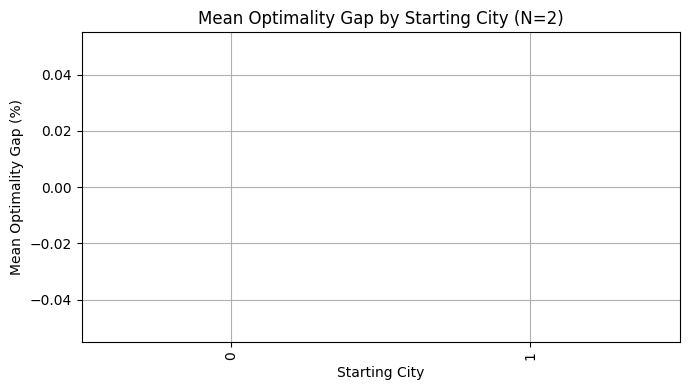

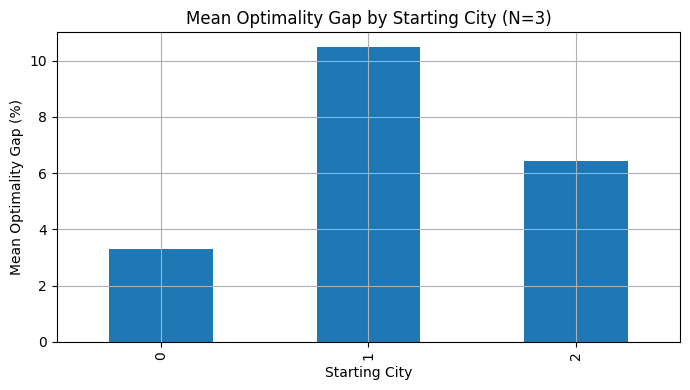

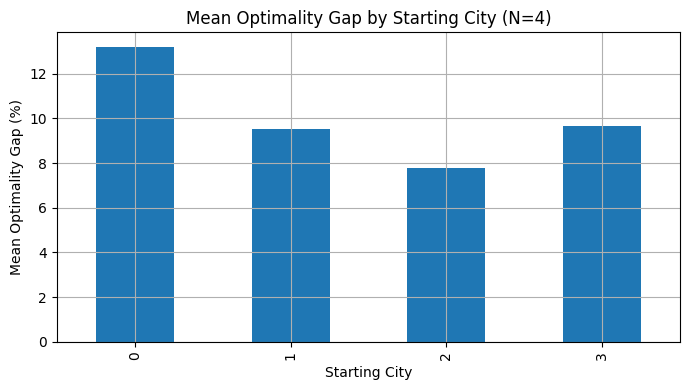

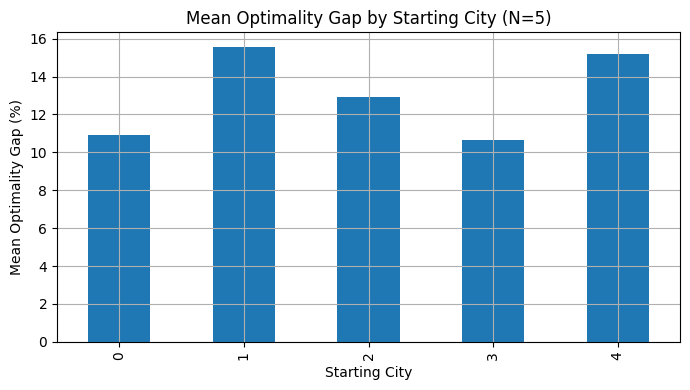

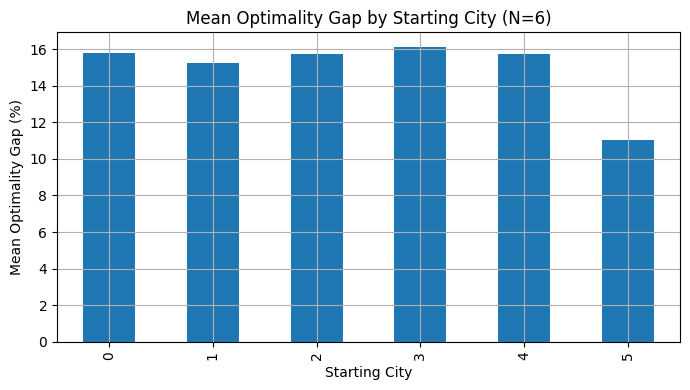

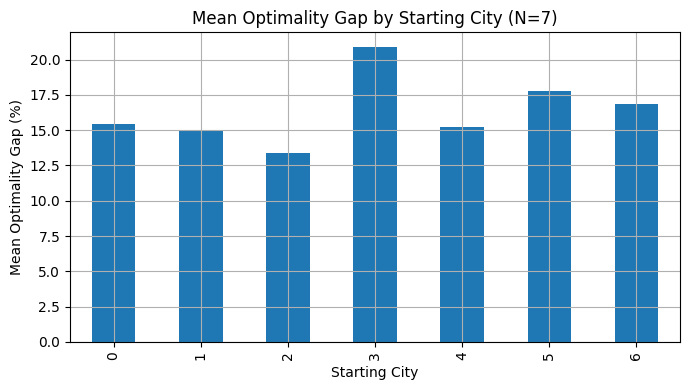

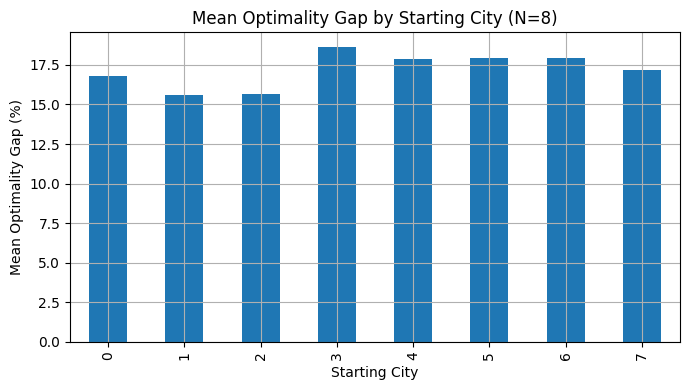

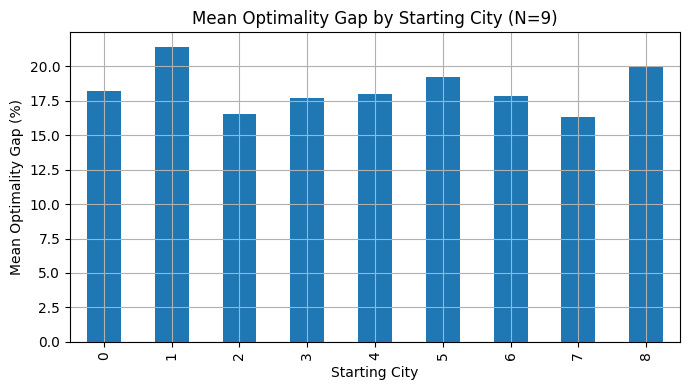

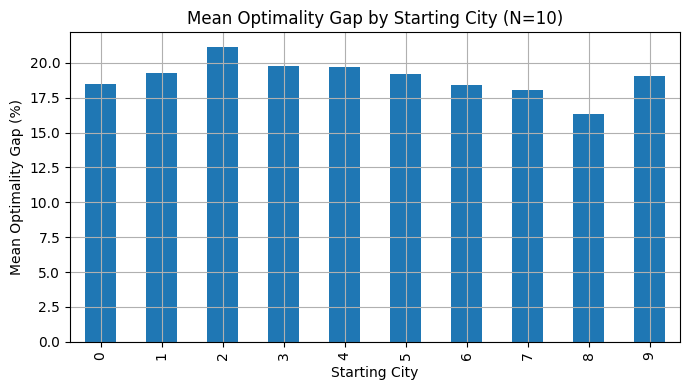

In [9]:
import matplotlib.pyplot as plt

# Analyze the effect of the starting city for each problem size.
for N in sorted(df["N"].unique()):

    # Select the observations corresponding to the current problem size.
    subset = df[df["N"] == N]

    # Calculate the mean optimality gap for each starting city.
    start_analysis = subset.groupby("start")["gap_percent"].mean()

    # Create a bar chart to compare starting cities.
    plt.figure(figsize=(7, 4))
    start_analysis.plot(
        kind="bar",
        xlabel="Starting City",
        ylabel="Mean Optimality Gap (%)",
        title=f"Mean Optimality Gap by Starting City (N={N})",
        grid=True
    )

    # Adjust the layout and display the chart.
    plt.tight_layout()
    plt.show()

### Starting City Comparison Table

This section summarizes the mean optimality gap for each problem size and starting city in a pivot table.

The table provides a compact overview of how the starting city affects the solution quality of the Nearest Neighbor algorithm across different problem sizes.

In [10]:
# Calculate the mean optimality gap for each problem size and starting city.
gap_table = df.pivot_table(
    index="N",
    columns="start",
    values="gap_percent",
    aggfunc="mean"
)

# Display the table with values rounded to two decimal places.
display(gap_table.round(2))

start,0,1,2,3,4,5,6,7,8,9
N,,,,,,,,,,
2,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3.30,10.48,6.42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,13.19,9.53,7.79,9.66,NaN,NaN,NaN,NaN,NaN,NaN
5,10.91,15.55,12.93,10.65,15.20,NaN,NaN,NaN,NaN,NaN
6,15.76,15.26,15.73,16.11,15.73,11.03,NaN,NaN,NaN,NaN
7,15.44,14.91,13.36,20.89,15.23,17.75,16.88,NaN,NaN,NaN
8,16.82,15.59,15.63,18.62,17.88,17.96,17.94,17.20,NaN,NaN
9,18.17,21.39,16.50,17.73,17.98,19.23,17.86,16.30,20.00,NaN
10,18.51,19.26,21.12,19.78,19.69,19.21,18.39,18.08,16.32,19.06


### Best and Worst Starting City Analysis

This section identifies the best and worst starting cities for each problem size based on their mean optimality gaps.

The difference between the best and worst mean gaps is also calculated to evaluate how strongly the choice of starting city affects the solution quality of the Nearest Neighbor algorithm.

In [11]:
# Initialize a list to store the summary for each problem size.
summary_rows = []

# Analyze the starting city performance for each problem size.
for N, group in gap_table.iterrows():

    # Exclude missing values for starting cities that do not exist.
    valid = group.dropna()

    # Identify the starting city with the lowest mean optimality gap.
    best_start = valid.idxmin()

    # Identify the starting city with the highest mean optimality gap.
    worst_start = valid.idxmax()

    # Store the best, worst, and difference in mean optimality gaps.
    summary_rows.append({
        "N": N,
        "Best start": best_start,
        "Best mean gap (%)": valid.min(),
        "Worst start": worst_start,
        "Worst mean gap (%)": valid.max(),
        "Difference (percentage points)": valid.max() - valid.min()
    })

# Convert the summary into a DataFrame and use N as the index.
starting_city_summary = pd.DataFrame(summary_rows).set_index("N")

# Display the summary rounded to two decimal places.
display(starting_city_summary.round(2))

,Best start,Best mean gap (%),Worst start,Worst mean gap (%),Difference (percentage points)
N,,,,,
2,0,0.00,0,0.00,0.00
3,0,3.30,1,10.48,7.18
4,2,7.79,0,13.19,5.40
5,3,10.65,1,15.55,4.90
6,5,11.03,3,16.11,5.08
7,2,13.36,3,20.89,7.53
8,1,15.59,3,18.62,3.03
9,7,16.30,1,21.39,5.10
10,8,16.32,2,21.12,4.81


### Save Starting City Analysis Results

This section exports the starting city analysis tables as CSV files. These files preserve the detailed mean optimality gaps and the summary of the best and worst starting cities for each problem size.

In [12]:
# Save the starting city comparison table.
gap_table.round(2).to_csv(
    data_dir / "starting_city_gap_table.csv"
)

# Save the best and worst starting city summary.
starting_city_summary.round(2).to_csv(
    data_dir / "starting_city_summary.csv"
)

### Runtime Analysis

This section compares the computational runtime of the Brute Force and Nearest Neighbor algorithms across different problem sizes.

For each problem size, the mean, median, and standard deviation of the execution times are calculated. These statistics help evaluate the computational efficiency and runtime variability of both algorithms.

In [13]:
# Calculate runtime statistics for both algorithms for each problem size.
time_analysis = df.groupby("N")[
    ["bf_duration_ms", "nn_duration_ms"]
].agg(["mean", "median", "std"])

# Display the runtime analysis results.
display(time_analysis)

bf_duration_ms                         nn_duration_ms                   
             mean      median         std           mean   median       std
N                                                                          
2        0.008516     0.00780    0.002966       0.005301  0.00485  0.001431
3        0.011098     0.01030    0.003755       0.007228  0.00710  0.000903
4        0.029691     0.02420    0.035461       0.012467  0.01030  0.011651
5        0.137826     0.08745    0.534609       0.016099  0.01370  0.012134
6        0.361223     0.30630    0.254356       0.014196  0.01175  0.007821
7        2.801889     2.20255    2.386643       0.031775  0.01920  0.161567
8       19.322068    16.83450    8.159038       0.032591  0.02400  0.061830
9      140.792873   131.29050   26.728639       0.037533  0.03155  0.026973
10    1294.715411  1250.85545  103.523020       0.042087  0.03700  0.014602

### Runtime Comparison Visualization

This section visualizes the average execution time of the Brute Force and Nearest Neighbor algorithms for different problem sizes.

A logarithmic scale is used on the vertical axis to make the runtime differences between the two algorithms easier to observe, particularly when their execution times differ by several orders of magnitude.

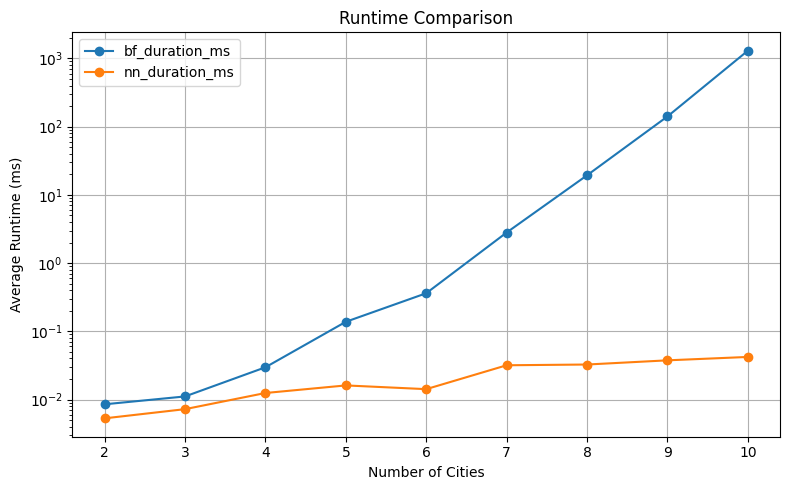

In [14]:
import matplotlib.pyplot as plt

# Calculate the mean execution time of both algorithms for each problem size.
time_means = df.groupby("N")[
    ["bf_duration_ms", "nn_duration_ms"]
].mean()

# Plot the average runtimes of both algorithms.
time_means.plot(marker="o", figsize=(8, 5))

# Use a logarithmic scale to display large differences in runtime.
plt.yscale("log")

# Add axis labels and chart title.
plt.xlabel("Number of Cities")
plt.ylabel("Average Runtime (ms)")
plt.title("Runtime Comparison")

# Display grid lines and the plot.
plt.grid(True)
plt.tight_layout()
plt.show()

### Optimality Gap Visualization

This section visualizes the average optimality gap of the Nearest Neighbor algorithm across different problem sizes.

The plot illustrates how the solution quality of the heuristic algorithm changes as the number of cities increases.

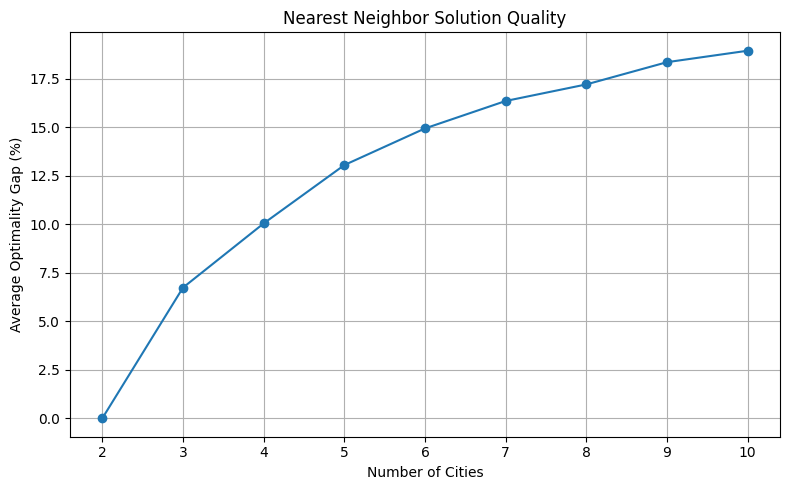

In [15]:
# Calculate the mean optimality gap for each problem size.
gap_means = df.groupby("N")["gap_percent"].mean()

# Plot the average optimality gap.
gap_means.plot(marker="o", figsize=(8, 5))

# Add axis labels and chart title.
plt.xlabel("Number of Cities")
plt.ylabel("Average Optimality Gap (%)")
plt.title("Nearest Neighbor Solution Quality")

# Display grid lines and the plot.
plt.grid(True)
plt.tight_layout()
plt.show()

### Solution Cost Comparison

This section compares the average tour costs obtained by the Brute Force and Nearest Neighbor algorithms across different problem sizes.

Since Brute Force provides the optimal solution, its average tour cost serves as a benchmark for evaluating the solution quality of the Nearest Neighbor heuristic.

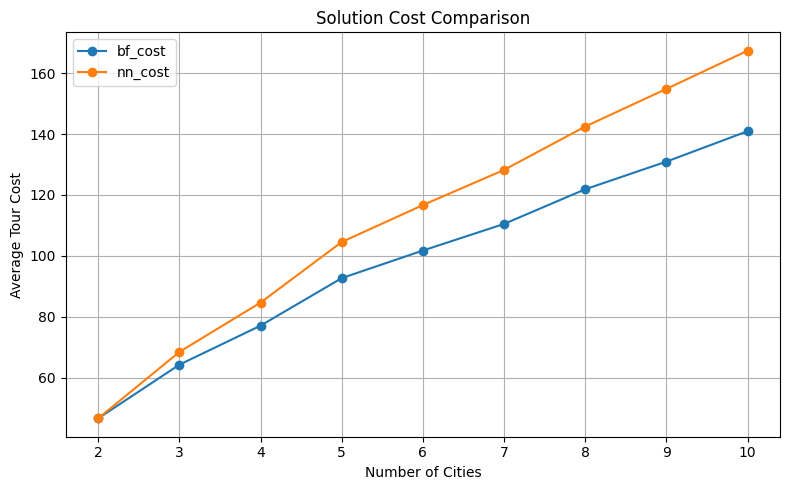

In [16]:
# Calculate the mean tour cost of both algorithms for each problem size.
cost_means = df.groupby("N")[
    ["bf_cost", "nn_cost"]
].mean()

# Plot the average tour costs of both algorithms.
cost_means.plot(marker="o", figsize=(8, 5))

# Add axis labels and chart title.
plt.xlabel("Number of Cities")
plt.ylabel("Average Tour Cost")
plt.title("Solution Cost Comparison")

# Display grid lines and the plot.
plt.grid(True)
plt.tight_layout()
plt.show()

## Conclusion

This notebook presents a computational comparison of the Brute Force and Nearest Neighbor algorithms for the Asymmetric Traveling Salesperson Problem (ATSP).

The experiments were conducted for problem sizes ranging from 2 to 10 cities, using 50 randomly generated cost matrices for each size and evaluating every possible starting city. The performance of both algorithms was compared in terms of solution quality, computational runtime, and optimality gap.

The results show that Brute Force consistently finds optimal solutions for the tested instances, making it a reliable benchmark for evaluating the Nearest Neighbor heuristic. However, its computational runtime increases rapidly as the problem size grows. In contrast, Nearest Neighbor is considerably faster, but does not always produce optimal solutions. Its solution quality also varies depending on the selected starting city.

For instances with 10 cities, the median runtime of Brute Force was approximately 1,250.86 ms, compared with 0.0370 ms for Nearest Neighbor. This corresponds to a runtime ratio of approximately 33,807, illustrating the substantial computational advantage of the heuristic for the tested instances.

The starting city analysis further indicates that the choice of initial city affects the solution quality of Nearest Neighbor, although no single starting city consistently provides the best results across all problem sizes.

Overall, the findings demonstrate the trade-off between optimality and computational efficiency in exact and heuristic optimization methods. Brute Force is suitable for small instances where finding the optimal solution is essential, whereas Nearest Neighbor offers a much faster alternative when computational efficiency is important. Further research could extend this comparison to larger problem instances and additional optimization algorithms.